# Threshold sensitivity check

CV RMSE between each tuned model's pairwise $\hat\chi$ and the target $\chi$, plotted against the threshold quantile level $q$, from

* `tune_threshold_hparams.py` (exchange-rate data, target: the empirical $\chi(0.98)$) → `Data_and_Model/threshold_sensitivity_nsf/`
* `tune_sim2s_hparams.py` (Simulation 2S, target: the reference $\chi(0.999)$) → `Data_and_Model/sim2s_nsf/`

The line shows the winning config of each $(q, \text{model})$ (`best_configs.json`). The faint points are all configs scored during the coordinate-wise sweep (`tuning/q{q}_{model}.json`).

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

DIR_OUT = "/home/pgrad2/2448355h/My_PhD_Project/GPDFlow/Data_and_Model/"
# Simulation first: it is the left panel
STUDIES = {
    'sim2s': dict(res_dir=DIR_OUT + 'sim2s_nsf/',
                  title='Simulation 2S', chi=r'\hat{\chi}(0.999)'),
    'exchange_rate': dict(res_dir=DIR_OUT + 'threshold_sensitivity_nsf/',
                          title='Exchange rate', chi=r'\hat{\chi}(0.98)'),
}
# Labels and colours as in Simulation_2S_cv_study.ipynb
MODELS = {'lik': ('GPDFlow (Likelihood)', 'darkgoldenrod'),
          'mmd': ('GPDFlow (MMD)', 'firebrick'),
          'bl': ('Probit-transformed NSF', 'steelblue'),
          'par': ('Parametric mGPD', 'seagreen')}
MARKERS = {'lik': 'o', 'mmd': 's', 'bl': '^', 'par': 'D'}

# Plot style as in Simulation_2S_cv_study.ipynb
sns.set(style="ticks", font_scale=1.3)
TITLE_FS = LABEL_FS = 18
LEGEND_FS = 15
TICK_FS = plt.rcParams['xtick.labelsize']

In [2]:
def load_best(res_dir):
    """best_configs.json -> DataFrame(q, model, cv_rmse_chi, median_epoch, cfg)."""
    with open(res_dir + 'best_configs.json') as f:
        best = json.load(f)
    rows = [dict(q=float(q), model=m, cv_rmse_chi=e['cv_rmse_chi'],
                 median_epoch=e['median_epoch'], cfg=e['cfg'])
            for q, per_model in best.items() for m, e in per_model.items()]
    return pd.DataFrame(rows).sort_values(['model', 'q']).reset_index(drop=True)


def load_sweep(res_dir):
    """All scored configs in tuning/q{q}_{model}.json -> DataFrame(q, model, rmse_chi)."""
    rows = []
    for fn in sorted(os.listdir(res_dir + 'tuning/')):
        if not (fn.startswith('q') and fn.endswith('.json')):
            continue
        q, model = fn[1:-5].split('_')
        with open(res_dir + 'tuning/' + fn) as f:
            rows += [dict(q=float(q), model=model, rmse_chi=r['rmse_chi']) for r in json.load(f)]
    df = pd.DataFrame(rows)
    return df[np.isfinite(df['rmse_chi'])]


best = {k: load_best(s['res_dir']) for k, s in STUDIES.items()}
sweep = {k: load_sweep(s['res_dir']) for k, s in STUDIES.items()}

## Winning CV RMSE per threshold

In [3]:
for k, s in STUDIES.items():
    print(s['title'], '| CV RMSE of', s['chi'])
    display(best[k].pivot(index='q', columns='model', values='cv_rmse_chi')
            [[m for m in MODELS if m in best[k]['model'].unique()]].round(4))

Simulation 2S | CV RMSE of \hat{\chi}(0.999)


model,lik,mmd,bl,par
q,,,,
0.95,0.0609,0.0320,0.1514,0.0660
0.96,0.0562,0.0274,0.0983,0.0698
0.97,0.0495,0.0266,0.1133,0.0832


Exchange rate | CV RMSE of \hat{\chi}(0.98)


model,lik,mmd,bl,par
q,,,,
0.950,0.0571,0.0404,0.0712,0.0617
0.960,0.0549,0.0389,0.0638,0.0644
0.970,0.0515,0.0330,0.0478,0.0682
0.975,0.0562,0.0362,0.0374,0.0707


## RMSE of $\chi$ over the searched quantile levels

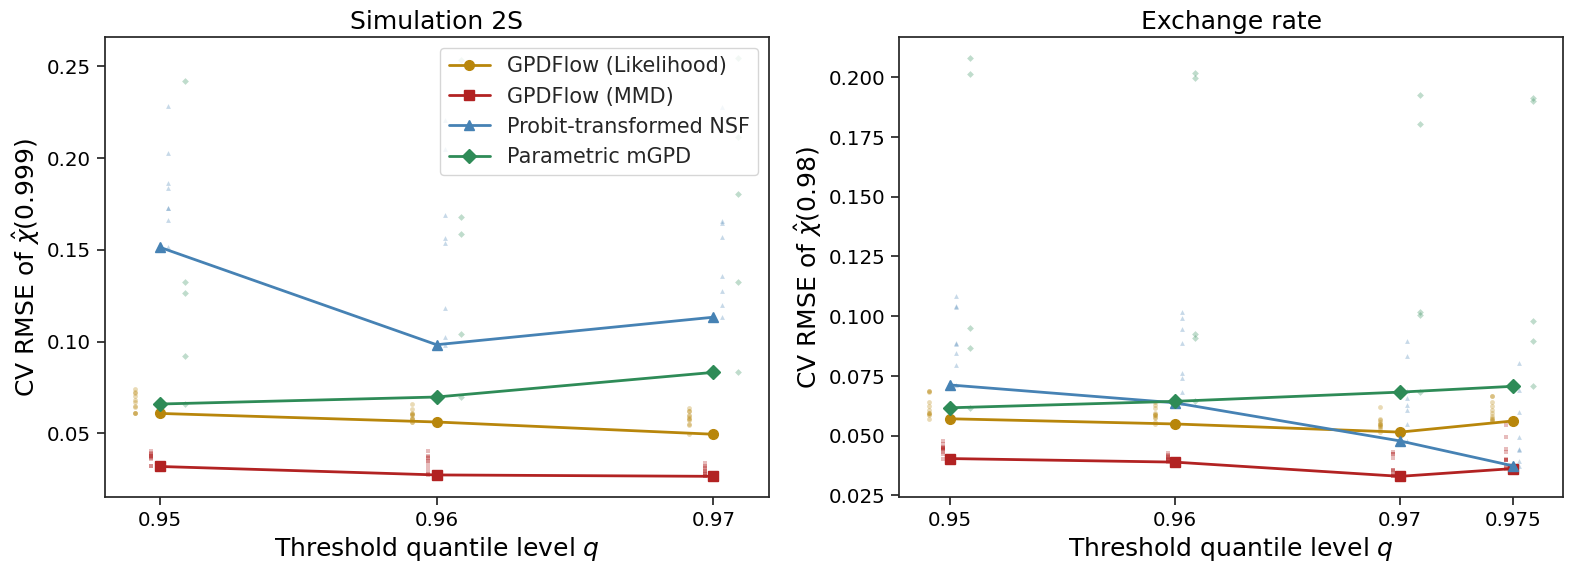

In [ ]:
fig, axes = plt.subplots(1, len(STUDIES), figsize=(8 * len(STUDIES), 6))
jitter = {m: (i - 1.5) * 0.0006 for i, m in enumerate(MODELS)}   # spread the sweep points
for ax, (k, s) in zip(np.atleast_1d(axes), STUDIES.items()):
    for m, (label, color) in MODELS.items():
        b = best[k][best[k]['model'] == m]
        if b.empty:
            continue
        sw = sweep[k][sweep[k]['model'] == m]
        ax.plot(b['q'], b['cv_rmse_chi'], marker=MARKERS[m], color=color, linewidth=2,
                markersize=7, label=label)
        ax.scatter(sw['q'] + jitter[m], sw['rmse_chi'], marker=MARKERS[m], s=12,
                   color=color, alpha=0.3, linewidths=0)
    qs = sorted(best[k]['q'].unique())
    ax.set_xticks(qs)
    ax.set_xticklabels([f'{q:g}' for q in qs])
    ax.set_xlabel('Threshold quantile level $q$', color='black', fontsize=LABEL_FS)
    ax.set_ylabel(rf"CV RMSE of ${s['chi']}$", color='black', fontsize=LABEL_FS)
    ax.set_title(s['title'], color='black', fontsize=TITLE_FS)
    ax.tick_params(axis='both', labelcolor='black', labelsize=TICK_FS)
# legend in the top-right corner of the simulation (left) panel
np.atleast_1d(axes)[0].legend(fontsize=LEGEND_FS, loc='upper right')
# fig.tight_layout()
# fig.savefig(DIR_OUT + 'Plots/threshold_sensitivity_rmse_chi.pdf', bbox_inches='tight')
# plt.show()

Zoom in on the winners only (without the sweep points, which can be far worse and stretch the y-axis), on a common y-scale for both studies:

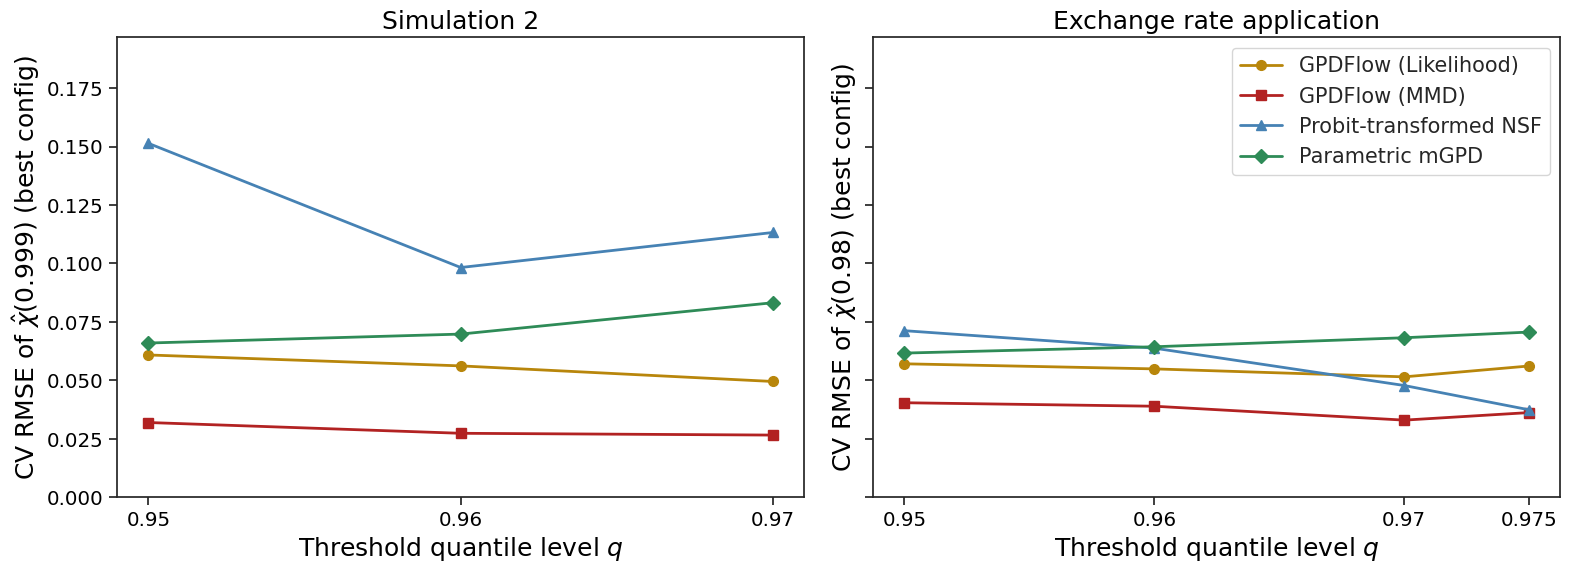

In [18]:
# one y-scale for both panels, starting at 0, so the RMSE levels are comparable;
# headroom above the highest winner keeps the legend clear of the lines
y_max = 1.3 * max(b['cv_rmse_chi'].max() for b in best.values())
fig, axes = plt.subplots(1, len(STUDIES), figsize=(8 * len(STUDIES), 6), sharey=True)
for ax, (k, s) in zip(np.atleast_1d(axes), STUDIES.items()):
    for m, (label, color) in MODELS.items():
        b = best[k][best[k]['model'] == m]
        if not b.empty:
            ax.plot(b['q'], b['cv_rmse_chi'], marker=MARKERS[m], color=color,
                    linewidth=2, markersize=7, label=label)
    qs = sorted(best[k]['q'].unique())
    ax.set_xticks(qs)
    ax.set_xticklabels([f'{q:g}' for q in qs])
    ax.set_xlabel('Threshold quantile level $q$', color='black', fontsize=LABEL_FS)
    ax.set_ylabel(rf"CV RMSE of ${s['chi']}$ (best config)", color='black', fontsize=LABEL_FS)
    ax.set_title(s['title'], color='black', fontsize=TITLE_FS)
    ax.tick_params(axis='both', labelcolor='black', labelsize=TICK_FS)
# legend in the top-right corner of the simulation (left) panel
np.atleast_1d(axes)[0].set_ylim(0, y_max)
np.atleast_1d(axes)[1].legend(fontsize=LEGEND_FS, loc='upper right')
fig.tight_layout()
fig.savefig(DIR_OUT + 'Plots/threshold_sensitivity_rmse_chi.pdf', bbox_inches='tight')
plt.show()